In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'


## **Exploratory Analysis and Data Cleaning**

In [3]:
df = pd.read_csv(data)

In [4]:
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [5]:
df.columns = df.columns.str.lower()

In [8]:
status_variables = {
    1: 'ok', 
    2: 'default', 
    0: 'unk'
}

df.status = df.status.map(status_variables)

home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk',
}
df.home = df.home.map(home_values)

marital_status = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}
df.marital = df.marital.map(marital_status)


record_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}
df.records = df.records.map(record_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}
df.job = df.job.map(job_values)


In [9]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [10]:
df.isna().sum()

status       0
seniority    0
home         0
time         0
age          0
marital      0
records      0
job          0
expenses     0
income       0
assets       0
debt         0
amount       0
price        0
dtype: int64

In [11]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [12]:
for c in ['income', 'assets', 'debt']:

    df[c] = df[c].replace(to_replace = 99999999.0, value = np.nan)

In [13]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [14]:
df['status'].value_counts()

status
ok         3200
default    1254
unk           1
Name: count, dtype: int64

In [15]:
df = df[df.status != 'unk'].reset_index(drop = True)

In [16]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129.0,0.0,0.0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131.0,0.0,0.0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200.0,3000.0,0.0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182.0,2500.0,0.0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107.0,0.0,0.0,310,910


In [17]:
df_full_train, df_test = train_test_split(
        df, 
        test_size=0.2, 
        random_state = 11
    )
df_train, df_val = train_test_split(
        df_full_train, 
        test_size=0.25, 
        random_state = 11
    )

In [18]:
df_full_train.shape, df_val.shape, df_test.shape

((3563, 14), (891, 14), (891, 14))

In [19]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [20]:
y_train = (df_train.status == 'default').astype('int').values
y_train_full = (df_full_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

In [21]:
y_val

array([0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,

In [22]:
del df_train['status']
del df_val['status']
del df_test['status']

In [23]:
df_train.columns

Index(['seniority', 'home', 'time', 'age', 'marital', 'records', 'job',
       'expenses', 'income', 'assets', 'debt', 'amount', 'price'],
      dtype='str')

## **model training**

### **1. logistic regression**

In [24]:
num_cols = df_train.select_dtypes(include = "number").columns.to_list()
cat_cols = [c for c in df_train.columns if c not in num_cols]

features = num_cols + cat_cols

print(f"features: {features}")
print(f"num_cols: {num_cols}")
print(f"cat_cols: {cat_cols}")

features: ['seniority', 'time', 'age', 'expenses', 'income', 'assets', 'debt', 'amount', 'price', 'home', 'marital', 'records', 'job']
num_cols: ['seniority', 'time', 'age', 'expenses', 'income', 'assets', 'debt', 'amount', 'price']
cat_cols: ['home', 'marital', 'records', 'job']


In [25]:
df_train.isna().sum()

seniority     0
home          0
time          0
age           0
marital       0
records       0
job           0
expenses      0
income       25
assets       30
debt         11
amount        0
price         0
dtype: int64

In [26]:
df[features].copy()

,seniority,time,age,expenses,income,assets,debt,amount,price,home,marital,records,job
0,9,60,30,73,129.0,0.0,0.0,800,846,rent,married,no,freelance
1,17,60,58,48,131.0,0.0,0.0,1000,1658,rent,widow,no,fixed
2,10,36,46,90,200.0,3000.0,0.0,2000,2985,owner,married,yes,freelance
3,0,60,24,63,182.0,2500.0,0.0,900,1325,rent,single,no,fixed
4,0,36,26,46,107.0,0.0,0.0,310,910,rent,single,no,fixed
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4449,1,60,39,69,92.0,0.0,0.0,900,1020,rent,married,no,fixed
4450,22,60,46,60,75.0,3000.0,600.0,950,1263,owner,married,no,fixed
4451,0,24,37,60,90.0,3500.0,0.0,500,963,owner,married,no,partime
4452,0,48,23,49,140.0,0.0,0.0,550,550,rent,single,no,freelance


In [27]:
def to_records(df):
    X = df[features].copy()
    # X[cat_cols] = X[cat_cols].fillna("missing")      # stateless, so safe to do here
    # X[num_cols] = X[num_cols].fillna("median")  
        # stateless, so safe to do here
    return X.to_dict(orient="records")

In [28]:
df_train.to_dict(orient = "records")

[{'seniority': 10,
  'home': 'owner',
  'time': 36,
  'age': 36,
  'marital': 'married',
  'records': 'no',
  'job': 'freelance',
  'expenses': 75,
  'income': 0.0,
  'assets': 10000.0,
  'debt': 0.0,
  'amount': 1000,
  'price': 1400},
 {'seniority': 6,
  'home': 'parents',
  'time': 48,
  'age': 32,
  'marital': 'single',
  'records': 'yes',
  'job': 'fixed',
  'expenses': 35,
  'income': 85.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 1100,
  'price': 1330},
 {'seniority': 1,
  'home': 'parents',
  'time': 48,
  'age': 40,
  'marital': 'married',
  'records': 'no',
  'job': 'fixed',
  'expenses': 75,
  'income': 121.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 1320,
  'price': 1600},
 {'seniority': 1,
  'home': 'parents',
  'time': 48,
  'age': 23,
  'marital': 'single',
  'records': 'no',
  'job': 'partime',
  'expenses': 35,
  'income': 72.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 1078,
  'price': 1079},
 {'seniority': 5,
  'home': 'owner',
  'time': 36,
  'age': 46,
  'm

In [29]:
X_train = to_records(df_train)
X_val = to_records(df_val)
X_test = to_records(df_test)

In [30]:
def make_pipe_lr(C = 1):
    
    pipe = make_pipeline(
    DictVectorizer(sparse = False),
    SimpleImputer(strategy = "median"),
    StandardScaler(),
    LogisticRegression(
        C = C, 
        max_iter = 1000,
        solver = "liblinear",
        # # penalty = "l2",

        )
    )
    
    return pipe

In [32]:
p = make_pipe_lr(C = 1).fit(X_train, y_train)
p

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [68]:
auc_train  = roc_auc_score(y_train, p.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val,   p.predict_proba(X_val)[:, 1])

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")




auc_train: 0.8531223593037013
auc_val: 0.8212958029594827


In [34]:
p[0].get_feature_names_out()

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'job=unk', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

In [35]:
scores = {"C": [], "auc_train": [], "auc_val": []}

for c in [0.1, 0.01, 0.001, 0.0001, 1]:

    p =  make_pipe_lr(c).fit(X_train, y_train)
    auc_train  = roc_auc_score(y_train, p.predict_proba(X_train)[:, 1])
    auc_val = roc_auc_score(y_val,   p.predict_proba(X_val)[:, 1])

    scores["C"].append(c)
    scores["auc_train"].append(auc_train)
    scores["auc_val"].append(auc_val)

pd.DataFrame(scores)


,C,auc_train,auc_val
0,0.1000,0.852641,0.820460
1,0.0100,0.847673,0.816252
2,0.0010,0.835535,0.801213
3,0.0001,0.826563,0.789945
4,1.0000,0.853122,0.821296


In [36]:
gs = GridSearchCV(
    make_pipe_lr(),
    param_grid = {"logisticregression__C": [0.1, 0.01, 0.001, 0.0001, 1]},

    cv = StratifiedKFold(
        n_splits=5, 
        shuffle=True, 
        random_state=24
    ),
    scoring = "roc_auc",
    n_jobs = -1
)

gs.fit(X_train, y_train)
print(gs.best_params_, gs.best_score_)

results = pd.DataFrame(gs.cv_results_)[[
    "param_logisticregression__C",
    "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")


{'logisticregression__C': 1} 0.8462250229847623


In [37]:
results

,param_logisticregression__C,mean_test_score,std_test_score,rank_test_score
4,1.0000,0.846225,0.012078,1
0,0.1000,0.845898,0.012131,2
1,0.0100,0.840754,0.013659,3
2,0.0010,0.828952,0.014484,4
3,0.0001,0.821158,0.014142,5


In [38]:
X_full_train = to_records(df_full_train)

In [39]:
final_lr_model = make_pipe_lr(C = 1)

final_lr_model.fit(X_full_train, y_train_full)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [40]:
roc_auc_score(y_train_full, final_lr_model.predict_proba(X_full_train)[:, 1])

0.8463922024452482

In [128]:
lr_test_auc = roc_auc_score(y_test, final_lr_model.predict_proba(X_test)[:, 1])
lr_test_auc

0.8258210742387959

## **feature importance**

In [70]:
lr_model = final_lr_model.named_steps["logisticregression"]

coefficients = lr_model.coef_[0]
coefficients

array([ 0.10708336,  0.85316627, -0.34282208,  0.20142373,  0.30619748,
        0.04022379,  0.17344131, -0.1741392 , -0.06404191,  0.06446218,
        0.11546071,  0.06114298, -0.70292495, -0.22611135, -0.00295246,
        0.06337588,  0.31941723,  0.12451034,  0.02352947, -0.11834269,
        0.13967334,  0.05501453, -0.09714542,  0.04959281, -0.54464584,
       -0.35663871,  0.35663871, -0.64007228,  0.06709542])

In [71]:
feature_names = final_lr_model.named_steps["dictvectorizer"].get_feature_names_out()

feature_names

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'job=unk', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

In [72]:
important_df = pd.DataFrame({
    
    "features": feature_names,
    "coefficients": coefficients
})

important_df["absolute_coefficient"] = (important_df["coefficients"].abs())

important_df = important_df.sort_values("absolute_coefficient", ascending = False)

important_df.head(15)

,features,coefficients,absolute_coefficient
1,amount,0.853166,0.853166
12,income,-0.702925,0.702925
27,seniority,-0.640072,0.640072
24,price,-0.544646,0.544646
26,records=yes,0.356639,0.356639
25,records=no,-0.356639,0.356639
2,assets,-0.342822,0.342822
16,job=partime,0.319417,0.319417
4,expenses,0.306197,0.306197
13,job=fixed,-0.226111,0.226111


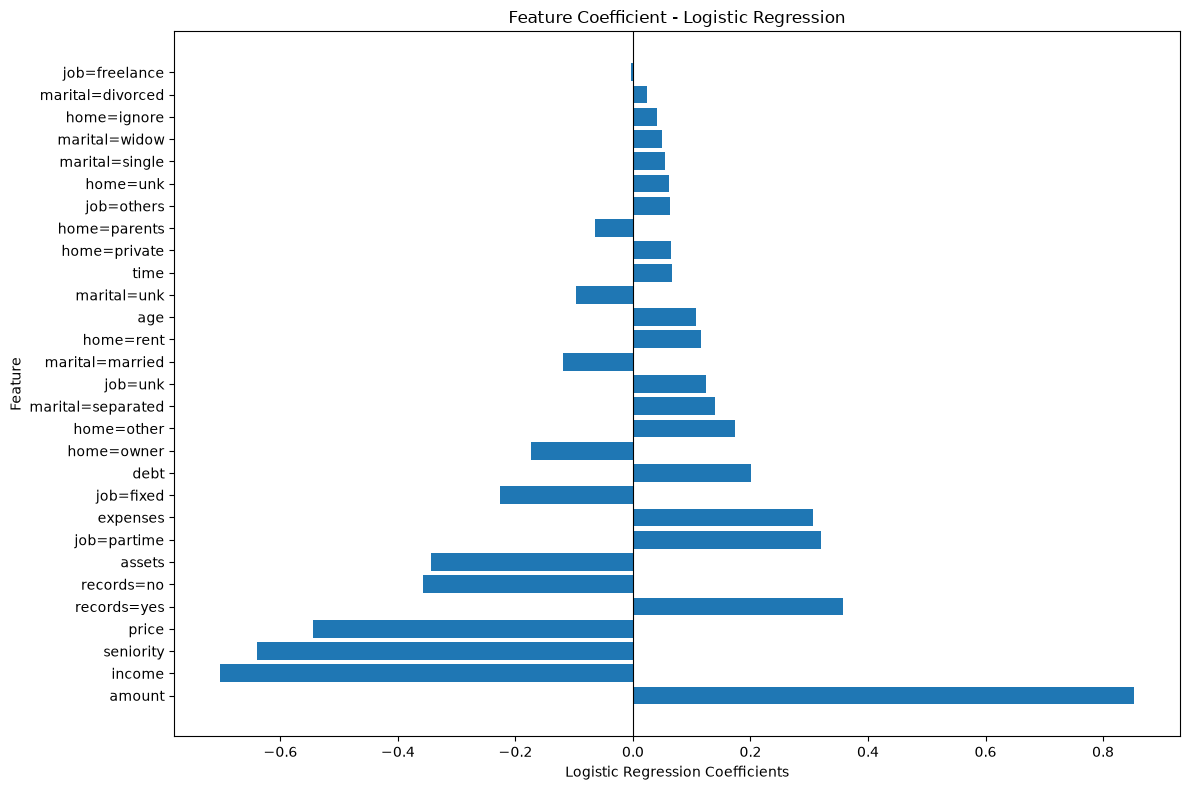

In [77]:
plt.figure(figsize = (12, 8))

plt.barh(important_df["features"], important_df["coefficients"])
plt.axvline(0, color = "black", linewidth = 0.8)
plt.xlabel("Logistic Regression Coefficients")
plt.ylabel("Feature")
plt.title("Feature Coefficient - Logistic Regression")
plt.tight_layout()
plt.show()

## **Decisiontree Classifier**

In [42]:
def make_pipe_dt(max_depth = None, min_samples_leaf = 1):
    
    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        # StandardScaler(),
        DecisionTreeClassifier(
            max_depth = max_depth,
            min_samples_leaf = min_samples_leaf,
            random_state = 24,

        )
    )
    
    return pipe

In [43]:
dt = make_pipe_dt().fit(X_train, y_train)
dt

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [44]:
auc_train  = roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val,   dt.predict_proba(X_val)[:, 1])

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")

auc_train: 1.0
auc_val: 0.6428973626213945


In [45]:
scores = {}

for max_depth in [3, 4, 5, None]:

    dt =  make_pipe_dt(max_depth = max_depth).fit(X_train, y_train)
    auc_train  = roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])
    auc_val = roc_auc_score(y_val,   dt.predict_proba(X_val)[:, 1])

    # scores["max_depth"].append(max_depth)
    # scores["auc_train"].append(auc_train)
    # scores["auc_val"].append(auc_val)
    scores[max_depth] = auc_train, auc_val

scores


{3: (0.7727018900343643, 0.7376244217868301),
 4: (0.8143667962368317, 0.7594239664818),
 5: (0.8416515266745537, 0.7668317551040178),
 None: (1.0, 0.6428973626213945)}

In [46]:
gs = GridSearchCV(
    estimator = make_pipe_dt(),
    param_grid = {"decisiontreeclassifier__max_depth": [3, 4, 5]},

    cv = StratifiedKFold(
        n_splits=5, 
        shuffle=True, 
        random_state=24
    ),
    scoring = "roc_auc",
    n_jobs = -1
)

gs.fit(X_train, y_train)
print(gs.best_params_, gs.best_score_)

results = pd.DataFrame(gs.cv_results_)[[
    "param_decisiontreeclassifier__max_depth",
    "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")

# gs.cv_results_

{'decisiontreeclassifier__max_depth': 4} 0.7793676692538335


In [47]:
results

,param_decisiontreeclassifier__max_depth,mean_test_score,std_test_score,rank_test_score
1,4,0.779368,0.015514,1
2,5,0.771438,0.023382,2
0,3,0.760085,0.016377,3


In [48]:
scores = {}

for min_samples_leaf in [10, 15, 20, 30, 40, 50]:

    dt =  make_pipe_dt(max_depth = 4, min_samples_leaf = min_samples_leaf).fit(X_train, y_train)
    auc_train  = roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])
    auc_val = roc_auc_score(y_val,   dt.predict_proba(X_val)[:, 1])

    # scores["max_depth"].append(max_depth)
    # scores["auc_train"].append(auc_train)
    # scores["auc_val"].append(auc_val)
    scores[min_samples_leaf] = auc_train, auc_val, round((auc_train-auc_val), 4)

scores


{10: (0.8143667962368317, 0.7594239664818, 0.0549),
 15: (0.8134429046250916, 0.7630688285582815, 0.0504),
 20: (0.8130457439017519, 0.7603261001186701, 0.0527),
 30: (0.8122549433834714, 0.757023322273619, 0.0552),
 40: (0.80847276209791, 0.7548678888861979, 0.0536),
 50: (0.80847276209791, 0.7548678888861979, 0.0536)}

In [49]:
gs = GridSearchCV(
    estimator = make_pipe_dt(),
    param_grid = {"decisiontreeclassifier__min_samples_leaf": [10, 15, 20, 30, 40, 50, 75, 100]},

    cv = StratifiedKFold(
        n_splits=5, 
        shuffle=True, 
        random_state=24
    ),
    scoring = "roc_auc",
    n_jobs = -1
)

gs.fit(X_train, y_train)
print(gs.best_params_, gs.best_score_)

results = pd.DataFrame(gs.cv_results_)[[
    "param_decisiontreeclassifier__min_samples_leaf",
    "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")

# gs.cv_results_

{'decisiontreeclassifier__min_samples_leaf': 50} 0.8106126676062319


In [50]:
results

,param_decisiontreeclassifier__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
5,50,0.810613,0.013964,1
4,40,0.807447,0.022821,2
6,75,0.805503,0.014597,3
7,100,0.804901,0.016950,4
3,30,0.800622,0.015860,5
2,20,0.783966,0.021369,6
1,15,0.778116,0.022054,7
0,10,0.768220,0.023931,8


In [78]:
dt = make_pipe_dt(max_depth = 4, min_samples_leaf = 50)

dt.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [80]:
roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])

0.80847276209791

In [81]:
roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])

0.7548678888861979

## **final model**

In [82]:
final_dt_model = make_pipe_dt(max_depth = 4, min_samples_leaf = 50)

final_dt_model.fit(X_full_train, y_train_full)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [126]:
print(f"train_auc: {roc_auc_score(y_train_full, final_dt_model.predict_proba(X_full_train)[:, 1])}")
print(f"test_auc: {roc_auc_score(y_test, final_dt_model.predict_proba(X_test)[:, 1])}")

train_auc: 0.7951789711798869
test_auc: 0.7601442989101217


In [127]:
dt_test_auc = roc_auc_score(y_test, final_dt_model.predict_proba(X_test)[:, 1])
dt_test_auc

0.7601442989101217

## **feature importance**

In [105]:
dt_model = final_dt_model.named_steps["decisiontreeclassifier"]

coefficients = dt_model.feature_importances_
coefficients

array([0.        , 0.0266979 , 0.05644801, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.18971747, 0.        , 0.        ,
       0.        , 0.22617876, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.32527319, 0.        , 0.16641441, 0.00927027])

In [106]:
feature_names = final_dt_model.named_steps["dictvectorizer"].get_feature_names_out()

feature_names

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'job=unk', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

In [107]:
important_df = pd.DataFrame({
    
    "features": feature_names,
    "coefficients": coefficients
})

important_df["absolute_coefficient"] = (important_df["coefficients"].abs())

important_df = important_df.sort_values("absolute_coefficient", ascending = False)

important_df.head(15)

,features,coefficients,absolute_coefficient
25,records=no,0.325273,0.325273
16,job=partime,0.226179,0.226179
12,income,0.189717,0.189717
27,seniority,0.166414,0.166414
2,assets,0.056448,0.056448
1,amount,0.026698,0.026698
28,time,0.009270,0.009270
7,home=owner,0.000000,0.000000
6,home=other,0.000000,0.000000
4,expenses,0.000000,0.000000


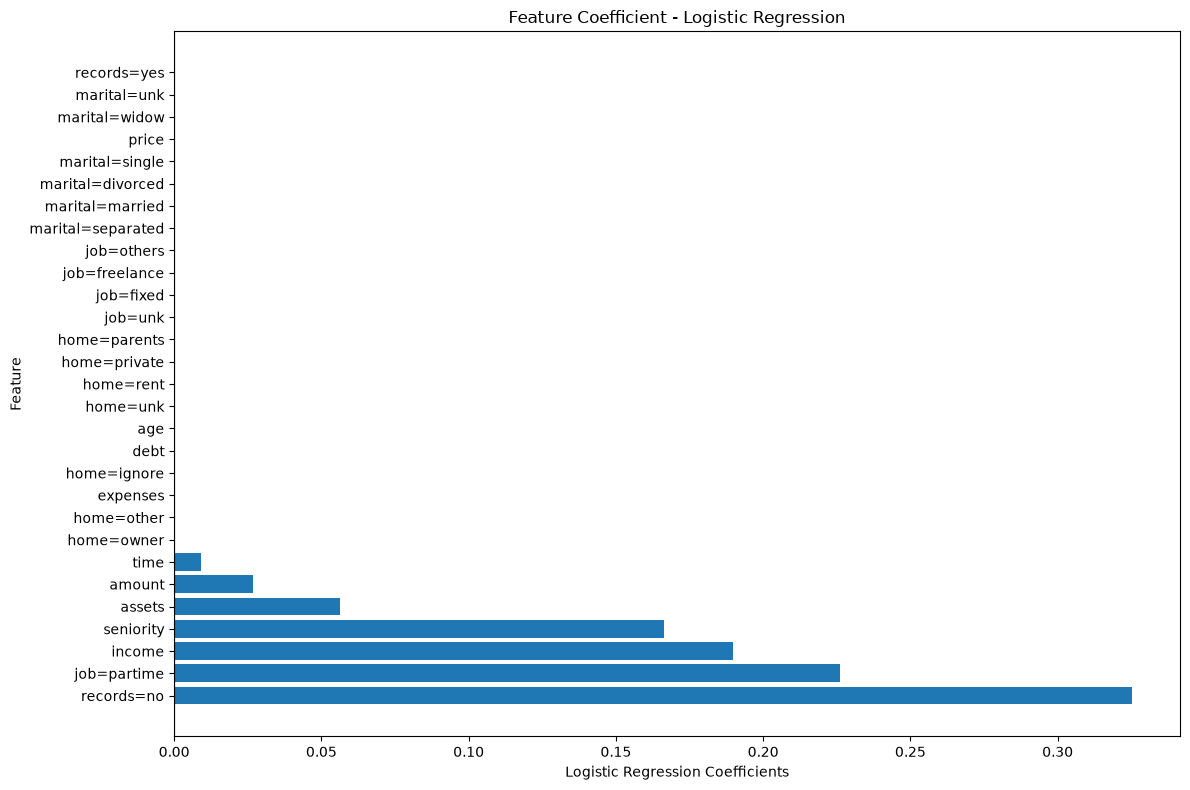

In [108]:
plt.figure(figsize = (12, 8))

plt.barh(important_df["features"], important_df["coefficients"])
plt.axvline(0, color = "black", linewidth = 0.8)
plt.xlabel("Logistic Regression Coefficients")
plt.ylabel("Feature")
plt.title("Feature Coefficient - Logistic Regression")
plt.tight_layout()
plt.show()

## **RandomForest**

In [54]:
def make_pipe_rf(n_estimators = 100, max_depth = None, min_samples_leaf = 1):
    
    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        # StandardScaler(),
        RandomForestClassifier(
            n_estimators = n_estimators,
            max_depth = max_depth,
            min_samples_leaf = min_samples_leaf,
            random_state = 24,
            n_jobs = -1

        )
    )
    
    return pipe

In [86]:
gs = GridSearchCV(
    estimator = make_pipe_rf(),
    param_grid = {
        "randomforestclassifier__n_estimators": [75, 100, 200, 300],
        "randomforestclassifier__max_depth": [15, 20, 30, 40, None],
        "randomforestclassifier__min_samples_leaf": [10, 15, 20],
    },

    cv = StratifiedKFold(
        n_splits=5, 
        shuffle=True, 
        random_state=24
    ),
    scoring = "roc_auc",
    n_jobs = -1
)


In [87]:
gs.fit(X_train, y_train)
print(gs.best_params_, gs.best_score_)

{'randomforestclassifier__max_depth': 20, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__n_estimators': 100} 0.8425132360527886


In [89]:
results = pd.DataFrame(gs.cv_results_)[[
    "param_randomforestclassifier__max_depth",
    "param_randomforestclassifier__min_samples_leaf",
    "param_randomforestclassifier__n_estimators",
    "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")
results.head(10)

,param_randomforestclassifier__max_depth,param_randomforestclassifier__min_samples_leaf,param_randomforestclassifier__n_estimators,mean_test_score,std_test_score,rank_test_score
13,20,10,100,0.842513,0.015347,1
25,30,10,100,0.842513,0.015347,1
49,None,10,100,0.842513,0.015347,1
37,40,10,100,0.842513,0.015347,1
15,20,10,300,0.842494,0.015316,5
51,None,10,300,0.842483,0.015310,6
39,40,10,300,0.842483,0.015310,6
27,30,10,300,0.842483,0.015310,6
3,15,10,300,0.842482,0.015218,9
1,15,10,100,0.842436,0.015521,10


In [90]:
rf = make_pipe_rf(n_estimators = 100, max_depth = 20, min_samples_leaf = 10)

rf.fit(X_train, y_train)

print(f"train_auc: {roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1])}")
print(f"val_auc: {roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])}")

train_auc: 0.9176088671060785
val_auc: 0.8162160034874426


## **final model**

In [91]:
final_rf_model = make_pipe_rf(max_depth = 20, min_samples_leaf = 10, n_estimators = 100)


final_rf_model.fit(X_full_train, y_train_full)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [92]:
roc_auc_score(y_train_full, final_rf_model.predict_proba(X_full_train)[:, 1])

0.9137789805726453

In [125]:
rf_test_auc = roc_auc_score(y_test, final_rf_model.predict_proba(X_test)[:, 1])
rf_test_auc

0.8225648795269047

## **feature importance**

In [96]:
rf_model = final_rf_model.named_steps["randomforestclassifier"]

coefficients = rf_model.feature_importances_
coefficients

array([4.75891320e-02, 7.82236458e-02, 7.29869779e-02, 9.79566698e-03,
       3.61068034e-02, 0.00000000e+00, 6.90458646e-03, 2.32156748e-02,
       7.13072780e-03, 1.68656787e-03, 1.33870552e-02, 0.00000000e+00,
       1.50217635e-01, 5.01857401e-02, 1.12559219e-02, 2.09462137e-03,
       6.26363987e-02, 0.00000000e+00, 5.12613301e-05, 6.19023017e-03,
       1.65515761e-03, 3.78539049e-03, 0.00000000e+00, 2.31700722e-04,
       5.98719671e-02, 9.21247064e-02, 1.02983885e-01, 1.31951201e-01,
       2.77373454e-02])

In [97]:
feature_names = final_rf_model.named_steps["dictvectorizer"].get_feature_names_out()

feature_names

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'job=unk', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

In [98]:
important_df = pd.DataFrame({
    
    "features": feature_names,
    "coefficients": coefficients
})

important_df["absolute_coefficient"] = (important_df["coefficients"].abs())

important_df = important_df.sort_values("absolute_coefficient", ascending = False)

important_df.head(15)

,features,coefficients,absolute_coefficient
12,income,0.150218,0.150218
27,seniority,0.131951,0.131951
26,records=yes,0.102984,0.102984
25,records=no,0.092125,0.092125
1,amount,0.078224,0.078224
2,assets,0.072987,0.072987
16,job=partime,0.062636,0.062636
24,price,0.059872,0.059872
13,job=fixed,0.050186,0.050186
0,age,0.047589,0.047589


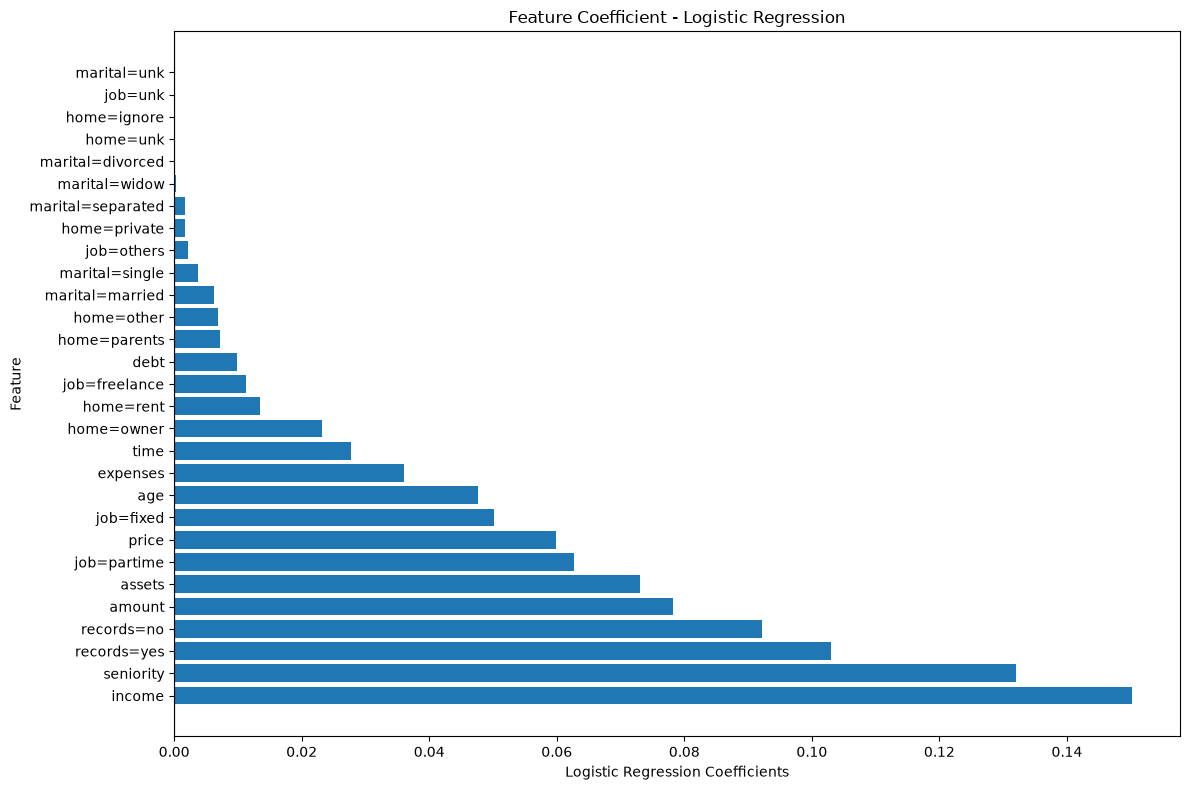

In [99]:
plt.figure(figsize = (12, 8))

plt.barh(important_df["features"], important_df["coefficients"])
plt.axvline(0, color = "black", linewidth = 0.8)
plt.xlabel("Logistic Regression Coefficients")
plt.ylabel("Feature")
plt.title("Feature Coefficient - Logistic Regression")
plt.tight_layout()
plt.show()

## **XGBoost**

In [132]:
def make_pipe_xgb(n_estimators = 100, max_depth = 3, learning_rate = 0.1):
    
    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        # StandardScaler(),
        xgb.XGBClassifier(
            n_estimators = n_estimators,
            max_depth = max_depth,
            learning_rate = learning_rate,
            eval_metric = "auc",
            random_state = 24,
            n_jobs = -1

        )
    )
    
    return pipe

In [133]:
gs = GridSearchCV(
    estimator = make_pipe_xgb(),
    param_grid = {
        "xgbclassifier__n_estimators": [75, 100, 200, 300],
        "xgbclassifier__max_depth": [3, 10, 15],
        "xgbclassifier__learning_rate": [0.001, 0.01, 0.1, 1],
    },

    cv = StratifiedKFold(
        n_splits=5, 
        shuffle=True, 
        random_state=24
    ),
    scoring = "roc_auc",
    n_jobs = -1
)


gs.fit(X_train, y_train)
print(gs.best_params_, gs.best_score_)




{'xgbclassifier__learning_rate': 0.1, 'xgbclassifier__max_depth': 3, 'xgbclassifier__n_estimators': 75} 0.8493444659321151


In [134]:
results = pd.DataFrame(gs.cv_results_)[[
    "param_xgbclassifier__n_estimators",
    "param_xgbclassifier__max_depth",
    "param_xgbclassifier__learning_rate",
    "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")

In [135]:
results

,param_xgbclassifier__n_estimators,param_xgbclassifier__max_depth,param_xgbclassifier__learning_rate,mean_test_score,std_test_score,rank_test_score
24,75,3,0.100,0.849344,0.021571,1
25,100,3,0.100,0.847307,0.023735,2
26,200,3,0.100,0.844440,0.024314,3
15,300,3,0.010,0.842830,0.016423,4
27,300,3,0.100,0.841232,0.025947,5
14,200,3,0.010,0.838090,0.015536,6
13,100,3,0.010,0.825154,0.014657,7
29,100,10,0.100,0.824599,0.026593,8
28,75,10,0.100,0.823502,0.024708,9
34,200,15,0.100,0.822182,0.025255,10


In [136]:
xgb_model= make_pipe_xgb(n_estimators = 75, max_depth = 3, learning_rate = 0.1)

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [138]:
print(f"train_auc : {roc_auc_score(y_train, xgb_model.predict_proba(X_train)[:, 1])}")
print(f"val_auc: {roc_auc_score(y_val, xgb_model.predict_proba(X_val)[:, 1])}")


train_auc : 0.9094139062588024
val_auc: 0.8297752536872441


In [139]:
final_xgb_model = make_pipe_xgb(n_estimators = 75, max_depth = 3, learning_rate = 0.1)

final_xgb_model.fit(X_full_train, y_train_full)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [140]:
roc_auc_score(y_train_full, final_xgb_model.predict_proba(X_full_train)[:, 1])

0.8939436277963024

In [142]:
xgb_test_auc = roc_auc_score(y_test, final_xgb_model.predict_proba(X_test)[:, 1])
xgb_test_auc

0.8331887493279899

## **picking the best model based on teSt_AUC**

In [144]:
lr_test_auc, dt_test_auc, rf_test_auc, xgb_test_auc

(0.8258210742387959,
 0.7601442989101217,
 0.8225648795269047,
 0.8331887493279899)

In [147]:
{
    "LogisticRegression": lr_test_auc,
    "decisiontree": dt_test_auc,
    "RandomForestClassifier": rf_test_auc,
    "xgboostclassifier": xgb_test_auc
}

{'LogisticRegression': 0.8258210742387959,
 'decisiontree': 0.7601442989101217,
 'RandomForestClassifier': 0.8225648795269047,
 'xgboostclassifier': 0.8331887493279899}